# Grouped validation, probability calibration and component explanations

Run python -m src.pipeline run first. This notebook reads saved evidence and does not retrain, tune thresholds, or overwrite reports.

In [1]:
from pathlib import Path
import sys
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/config.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import DATA_PATH, OUTPUTS, PRIMARY_SCORE
from src.data_cleaning import validate_raw_frame, clean_dataset, TARGET
from src.model_training import latest_run, load_bundle, predict_bundle, sha256_file, frame_hash
from src.backtesting import read_evidence
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.dpi': 110})
run_dir = latest_run()
oof, manifest = read_evidence(run_dir)
bundle, _ = load_bundle(run_dir)
for name, expected in manifest['source_sha256'].items():
    assert sha256_file(ROOT / 'src' / name) == expected, f'Source changed since training: {name}'
for name, expected in manifest['warehouse_source_sha256'].items():
    assert sha256_file(ROOT / 'sql' / name) == expected, f'SQL changed since training: {name}'
assert sha256_file(run_dir / 'training_snapshot.csv') == manifest['training_snapshot_sha256']
display(pd.Series({
    'training_run': manifest['run_id'], 'model_version': manifest['model_version'],
    'training_created_at_utc': manifest['created_at_utc'],
    'feature_reference_date': bundle['reference_date'],
    'validation_source': manifest['prediction_source'],
}).to_frame('saved evidence'))
print('Notebook review updated: 2026-10-11. Results come from the saved training run above.')


,saved evidence
training_run,f0095e2660d447bd9df382f307062afb
model_version,v2.1.0-grouped-sigmoid-unweighted
training_created_at_utc,2026-10-11T09:40:45.905842+00:00
feature_reference_date,2026-10-01
validation_source,grouped_oof


Notebook review updated: 2026-10-11. Results come from the saved training run above.


In [2]:
display(pd.Series({k: manifest[k] for k in ['run_id', 'validation_design', 'outer_folds',
                                          'inner_folds', 'primary_score', 'candidate_policy']}).to_frame('value'))
for fold in manifest['folds']:
    assert not set(fold['train_accounts']) & set(fold['validation_accounts'])
display(pd.DataFrame({'feature': bundle['preprocessor'].feature_names_}))


,value
run_id,f0095e2660d447bd9df382f307062afb
validation_design,account_grouped_outer_cv_inner_oof_calibration
outer_folds,5
inner_folds,3
primary_score,unweighted_ensemble_sigmoid
candidate_policy,Prespecified unweighted sigmoid ensemble; not ...


,feature
0,current_capacity_tb
1,is_over_utilized_raw
2,utilization_capped
3,is_negative_profit
4,signed_log_profit
5,days_to_contract_end
6,contract_year
7,contract_quarter
8,profit_per_tb
9,stress_index


## Fold isolation and persisted feature state

For each outer split: fit preprocessing and models using training accounts; generate inner grouped OOF probabilities within those training accounts; fit sigmoid/isotonic maps using those inner predictions; then score untouched outer accounts. Fit the final inference bundle on all labeled rows with final maps learned from grouped inner OOF predictions. Capacity quartiles are learned separately inside each training fold and saved for inference. Signed log and nominal expansion indicators require no population-wide fitted offset.

In [3]:
display(pd.DataFrame([
    {'fold': f['fold_id'], 'train_accounts': len(f['train_accounts']),
     'validation_accounts': len(f['validation_accounts']),
     'train_rows': f['train_rows'], 'validation_rows': f['validation_rows'],
     'train_event_rate': f['training_prevalence'], 'capacity_edges': f['capacity_edges']}
    for f in manifest['folds']
]))
assert oof.groupby('account_id').fold_id.nunique().eq(1).all()
assert not oof.duplicated(['account_id', 'array_id']).any()
assert sum(f['validation_rows'] for f in manifest['folds']) == len(oof)
display(pd.Series({
    'saved_preprocessor_fit_rows': bundle['preprocessor'].fit_rows_,
    'saved_capacity_edges': bundle['preprocessor'].capacity_edges_.tolist(),
    'seed': manifest['seed'], 'tree_counts': manifest['parameters'],
    'calibration_maps': {name: mapping.method for name, mapping in bundle['calibrators'].items()},
}).to_frame('value'))
display(pd.DataFrame([
    {'package': name, 'training_version': version,
     'notebook_version': importlib.metadata.version(name)}
    for name, version in manifest['versions'].items()
]))


,fold,train_accounts,validation_accounts,train_rows,validation_rows,train_event_rate,capacity_edges
0,1,796,199,1507,377,0.157266,"[None, 661.5, 1313.0, 1887.0, None]"
1,2,796,199,1507,377,0.159257,"[None, 671.5, 1310.0, 1897.0, None]"
2,3,796,199,1507,377,0.156603,"[None, 677.5, 1322.0, 1880.5, None]"
3,4,796,199,1507,377,0.158593,"[None, 706.5, 1313.0, 1863.0, None]"
4,5,796,199,1508,376,0.159151,"[None, 657.75, 1310.5, 1875.5, None]"


,value
saved_preprocessor_fit_rows,1884
saved_capacity_edges,"[-inf, 671.75, 1312.5, 1881.25, inf]"
seed,42
tree_counts,"{'xgb_estimators': 150, 'rf_estimators': 200}"
calibration_maps,"{'xgb_sigmoid': 'sigmoid', 'xgb_isotonic': 'is..."


,package,training_version,notebook_version
0,numpy,2.5.3,2.5.3
1,pandas,3.0.6,3.0.6
2,scikit-learn,1.9.1,1.9.1
3,xgboost,3.4.1,3.4.1
4,shap,0.53.0,0.53.0
5,matplotlib,3.11.2,3.11.2
6,tabulate,0.10.0,0.10.0


## Proper scores and baselines

Preprocessing fits inside every training fold. Sigmoid/isotonic mappings fit to inner grouped OOF probabilities. Ensemble weights are fixed at 0.6/0.4. Outer labels do not select the scoring candidate or action thresholds. AP means average precision.

,mean_probability,observed_rate,bias,brier,log_loss,roc_auc,average_precision,ece_equal_width,ece_equal_count,brier_lift_vs_5_pct
model,,,,,,,,,,
static_5,0.050000,0.158174,-1.081741e-01,0.144857,0.517027,0.500000,0.158174,1.081741e-01,0.108174,0.000000
training_prevalence,0.158173,0.158174,-6.483716e-07,0.133165,0.436668,0.491357,0.155553,6.483716e-07,0.004959,8.071123
logistic,0.158117,0.158174,-5.713940e-05,0.133386,0.437141,0.528420,0.171996,1.167378e-02,0.029564,7.918510
weighted_xgb_raw,0.392007,0.158174,2.338330e-01,0.206507,0.600878,0.523693,0.167561,2.354317e-01,0.235247,-42.559381
weighted_xgb_sigmoid,0.157854,0.158174,-3.204739e-04,0.133165,0.436666,0.500421,0.160228,3.204739e-04,0.025582,8.070889
weighted_xgb_isotonic,0.160505,0.158174,2.331141e-03,0.133234,0.436866,0.511063,0.161111,2.331141e-03,0.024166,8.023488
weighted_rf_raw,0.439119,0.158174,2.809451e-01,0.218297,0.628090,0.510410,0.169290,2.809451e-01,0.280945,-50.698587
weighted_rf_sigmoid,0.157956,0.158174,-2.180355e-04,0.133220,0.436888,0.491659,0.163200,2.180355e-04,0.013073,8.033193
weighted_rf_isotonic,0.159335,0.158174,1.161214e-03,0.133093,0.436272,0.517504,0.166091,1.305212e-03,0.009629,8.120618


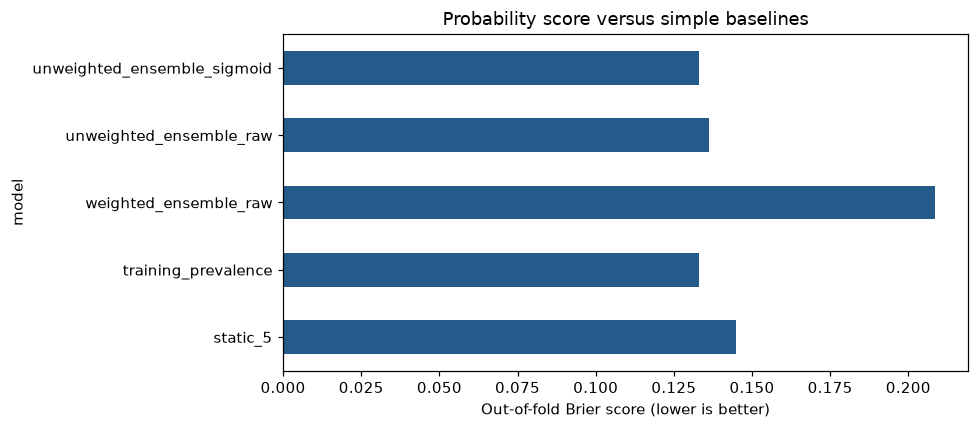

In [4]:
metrics = pd.read_csv(run_dir / 'metrics.csv').set_index('model')
display(metrics)
comparisons = ['static_5', 'training_prevalence', 'weighted_ensemble_raw',
               'unweighted_ensemble_raw', PRIMARY_SCORE]
metrics.loc[comparisons, 'brier'].plot.barh(color='#245b8a')
plt.xlabel('Out-of-fold Brier score (lower is better)')
plt.title('Probability score versus simple baselines')
plt.tight_layout()
plt.show()


## XGBoost versus Random Forest

The individual models are evaluated on the same account-isolated validation rows. Raw and sigmoid results show the effects of probability mapping. The prespecified ensemble remains an evaluated candidate; individual results are not used to select a new winner on these outer folds.

In [5]:
individuals = ['static_5', 'training_prevalence', 'unweighted_xgb_raw',
               'unweighted_rf_raw', 'unweighted_xgb_sigmoid', 'unweighted_rf_sigmoid', PRIMARY_SCORE]
display(metrics.loc[individuals, ['mean_probability', 'bias', 'brier', 'log_loss',
                                 'roc_auc', 'average_precision', 'ece_equal_count']])
individual_ci = pd.read_csv(run_dir / 'bootstrap_intervals.csv')
display(individual_ci.loc[individual_ci.model.isin(individuals)])


,mean_probability,bias,brier,log_loss,roc_auc,average_precision,ece_equal_count
model,,,,,,,
static_5,0.050000,-1.081741e-01,0.144857,0.517027,0.500000,0.158174,0.108174
training_prevalence,0.158173,-6.483716e-07,0.133165,0.436668,0.491357,0.155553,0.004959
unweighted_xgb_raw,0.154005,-4.168948e-03,0.138421,0.456958,0.526583,0.172597,0.054734
unweighted_rf_raw,0.158419,2.453167e-04,0.134568,0.441621,0.523721,0.171433,0.031569
unweighted_xgb_sigmoid,0.158121,-5.331569e-05,0.133153,0.436635,0.507274,0.170930,0.013142
unweighted_rf_sigmoid,0.157661,-5.127394e-04,0.133376,0.437471,0.488134,0.155305,0.021068
unweighted_ensemble_sigmoid,0.157952,-2.220276e-04,0.133202,0.436824,0.500004,0.166414,0.019726


,model,baseline,brier_gain,gain_ci_low,gain_ci_high,bias_ci_low,bias_ci_high
2,unweighted_xgb_raw,static_5,0.006436,0.001600,0.010859,-0.021511,0.012113
3,unweighted_xgb_raw,training_prevalence,-0.005256,-0.008145,-0.002559,-0.021511,0.012113
4,unweighted_xgb_sigmoid,static_5,0.011704,0.008146,0.015451,-0.017162,0.016188
5,unweighted_xgb_sigmoid,training_prevalence,0.000012,-0.000193,0.000213,-0.017162,0.016188
6,unweighted_rf_raw,static_5,0.010289,0.006020,0.014525,-0.016709,0.016222
7,unweighted_rf_raw,training_prevalence,-0.001403,-0.003098,0.000241,-0.016709,0.016222
8,unweighted_rf_sigmoid,static_5,0.011481,0.007973,0.015190,-0.017584,0.015794
9,unweighted_rf_sigmoid,training_prevalence,-0.000211,-0.000515,0.000090,-0.017584,0.015794
12,unweighted_ensemble_sigmoid,static_5,0.011654,0.008085,0.015435,-0.017390,0.016041
13,unweighted_ensemble_sigmoid,training_prevalence,-0.000037,-0.000289,0.000220,-0.017390,0.016041


Weighted candidates use fold-training class weights; unweighted candidates remove them. The logistic challenger fits a scaler and regularized logistic model within each outer fold. The prevalence challenger uses only that fold's training labels. Sigmoid maps fit a logistic mapping of clipped probability logits; isotonic maps fit monotonic probability mappings. Calibration changes probabilities; changing a classification threshold would not calibrate them. Risk buckets remain prespecified at 0.15, 0.40 and 0.70.

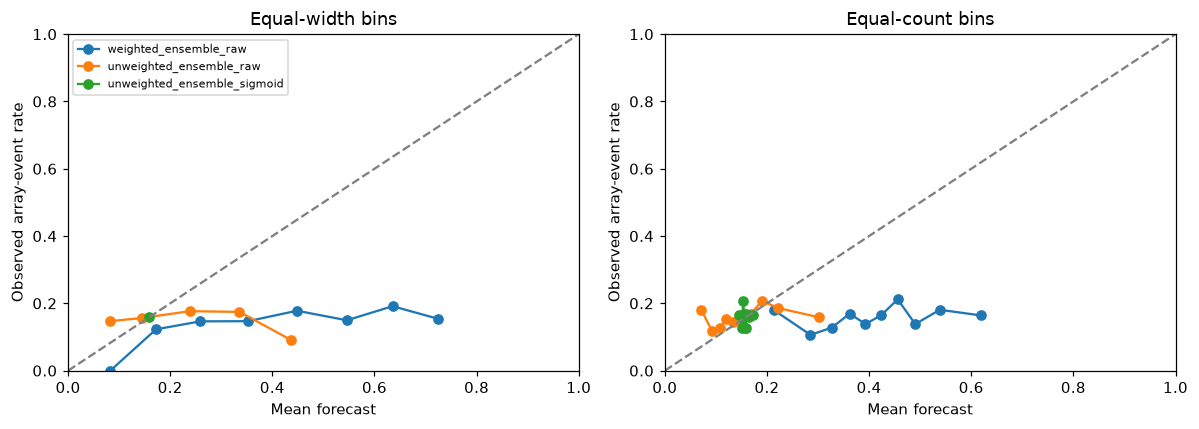

Small equal-width ECE alone does not demonstrate useful ranking.


In [6]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in ['weighted_ensemble_raw', 'unweighted_ensemble_raw', PRIMARY_SCORE]:
    for ax, strategy in zip(axes, ['uniform', 'quantile']):
        observed, forecast = calibration_curve(oof[TARGET], oof[name], n_bins=10, strategy=strategy)
        ax.plot(forecast, observed, marker='o', label=name)
for ax, title in zip(axes, ['Equal-width bins', 'Equal-count bins']):
    ax.plot([0, 1], [0, 1], '--', color='gray')
    ax.set(xlabel='Mean forecast', ylabel='Observed array-event rate', title=title, xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()
print('Small equal-width ECE alone does not demonstrate useful ranking.')


## Saved-state inference and honest SHAP units

This example scores an unlabeled array using saved state. SHAP explains only the raw XGB component in log-odds, not the mapped ensemble probability. It is associational, not causal.

In [7]:
from src.explainability import xgb_contributions, extract_top_shap_features
raw = validate_raw_frame(DATA_PATH)
example = raw.loc[raw[TARGET].isna()].iloc[:1].drop(columns=TARGET)
prediction = predict_bundle(bundle, example)
values, base, X = xgb_contributions(bundle, example)
display(example[['account_id', 'array_id']])
print('Mapped ensemble probability:', float(prediction['ensemble'][0]))
print('XGB raw margin:', float(values[0].sum() + base[0]))
display(extract_top_shap_features(values, bundle['preprocessor'].feature_names_))
all_unlabeled = raw.loc[raw[TARGET].isna()].drop(columns=TARGET)
saved_edges = bundle['preprocessor'].capacity_edges_.copy()
all_predictions = predict_bundle(bundle, all_unlabeled)
missing_target_predictions = predict_bundle(bundle, all_unlabeled.assign(**{TARGET: np.nan}))
for name in ['xgb', 'rf', 'ensemble']:
    assert np.isfinite(all_predictions[name]).all()
    np.testing.assert_allclose(all_predictions[name], missing_target_predictions[name])
np.testing.assert_array_equal(saved_edges, bundle['preprocessor'].capacity_edges_)
print('All unlabeled rows scored without refitting:', len(all_unlabeled))
raw_xgb_p = bundle['xgb'].predict_proba(X)[:, 1]
np.testing.assert_allclose(1 / (1 + np.exp(-(values.sum(axis=1) + base))), raw_xgb_p, atol=1e-6)


,account_id,array_id
44,ACC_1044,ARR_5044


Mapped ensemble probability: 0.15780976320755807
XGB raw margin: -1.227301836013794


,shap_top_feature_1,shap_top_feature_1_value,shap_top_feature_2,shap_top_feature_2_value,shap_top_feature_3,shap_top_feature_3_value
0,days_to_contract_end,0.206382,signed_log_profit,0.158161,profit_per_tb,0.095435


All unlabeled rows scored without refitting: 116


## Global component explanations

The four plots use the full supplied snapshot and the final fitted XGB component. They illustrate model associations and are not validation evidence. Full per-row contributions and base values are retained in the scoring sidecar; the CSV keeps the top three display features.

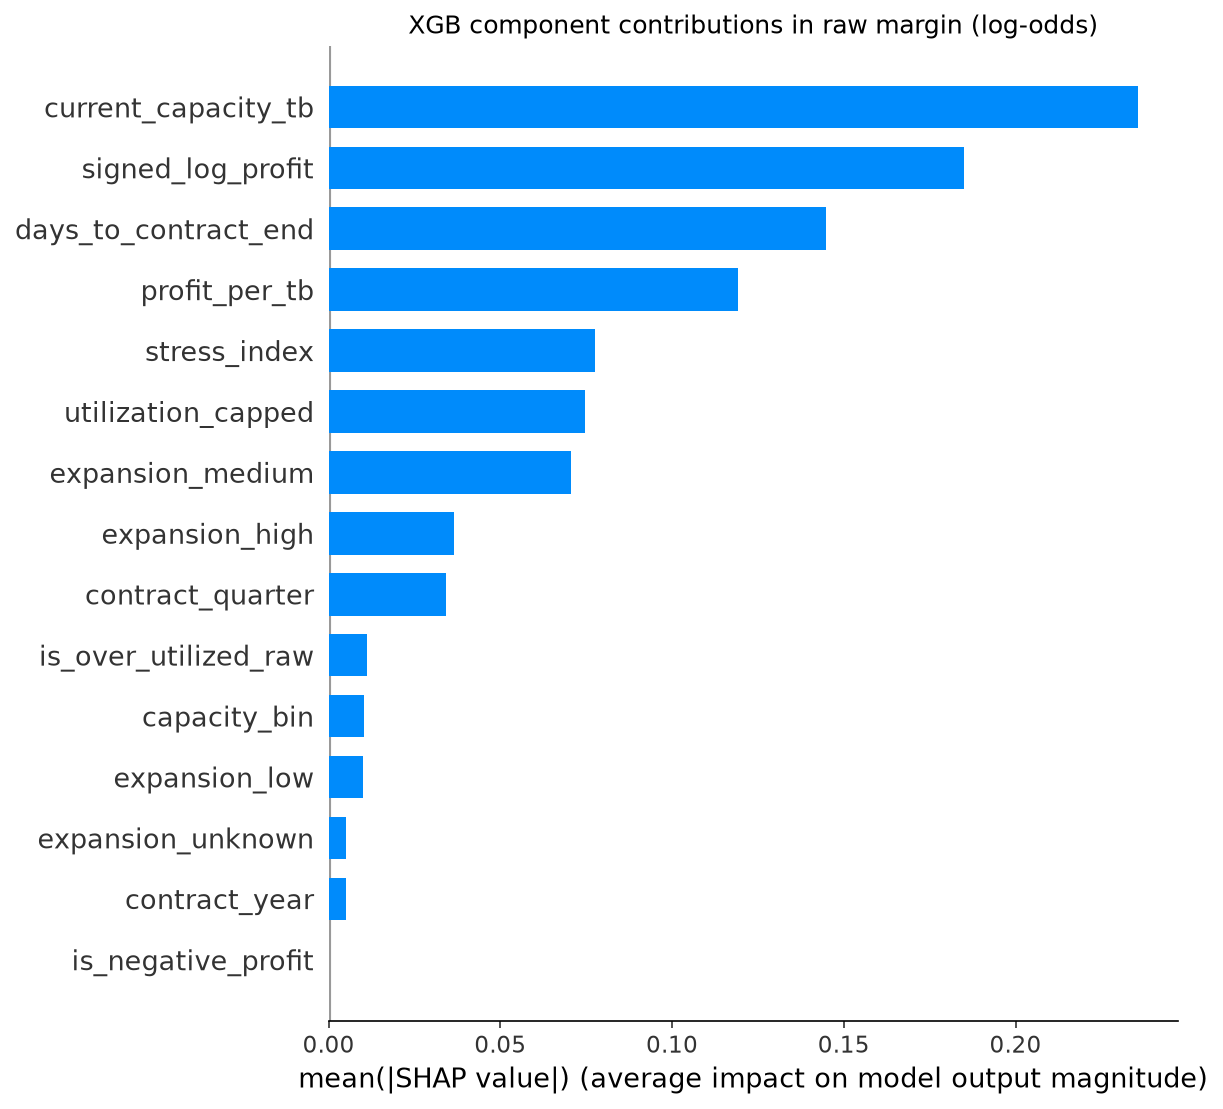

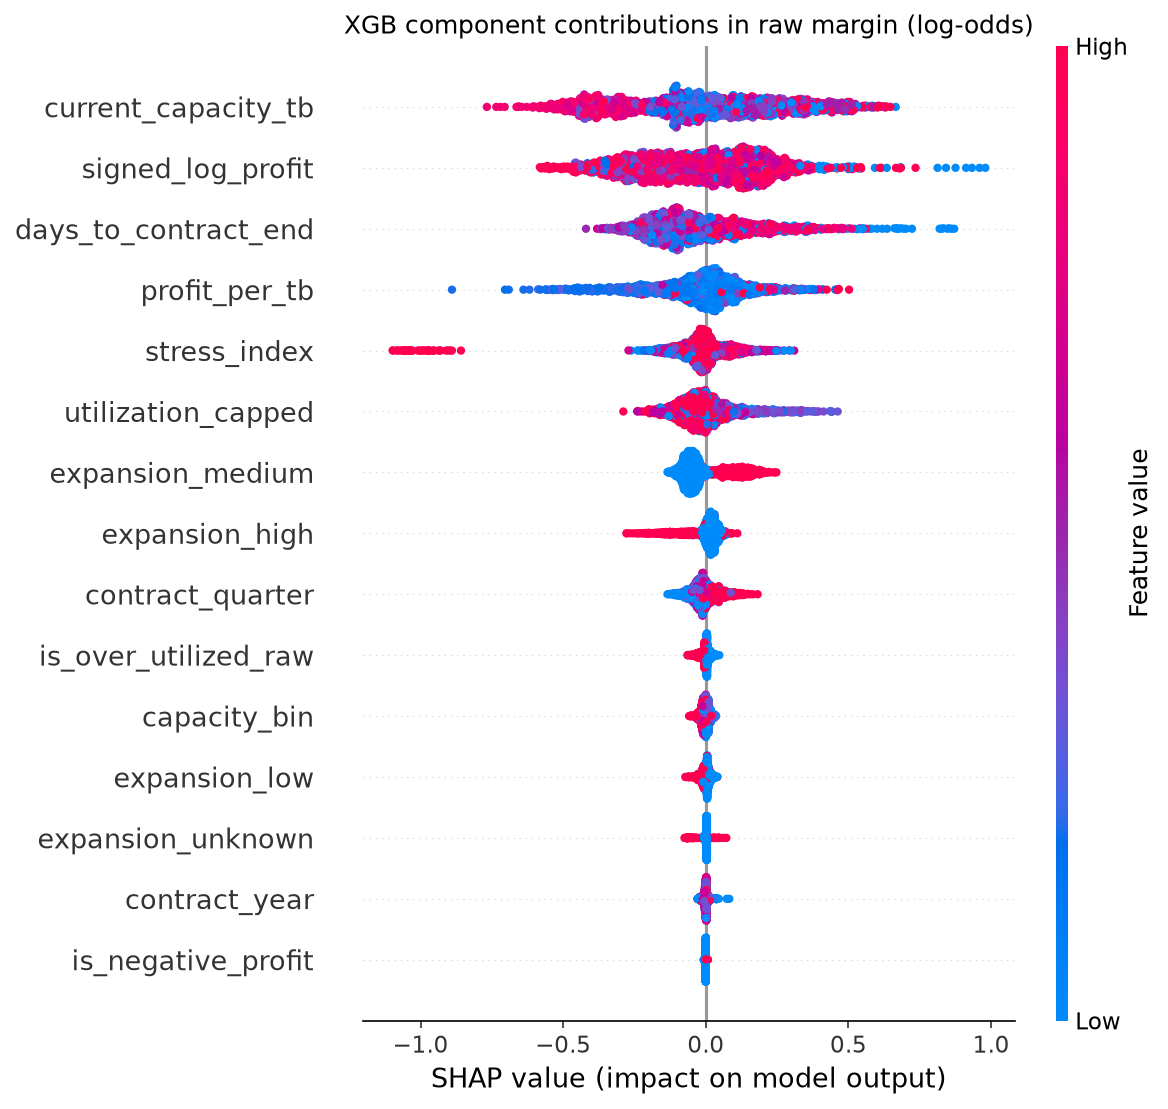

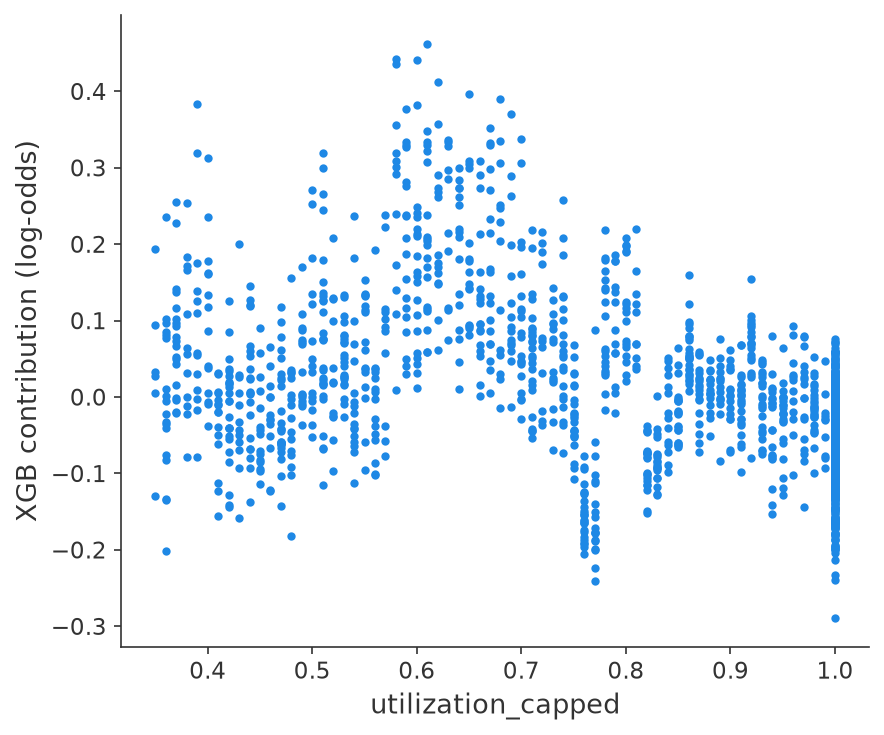

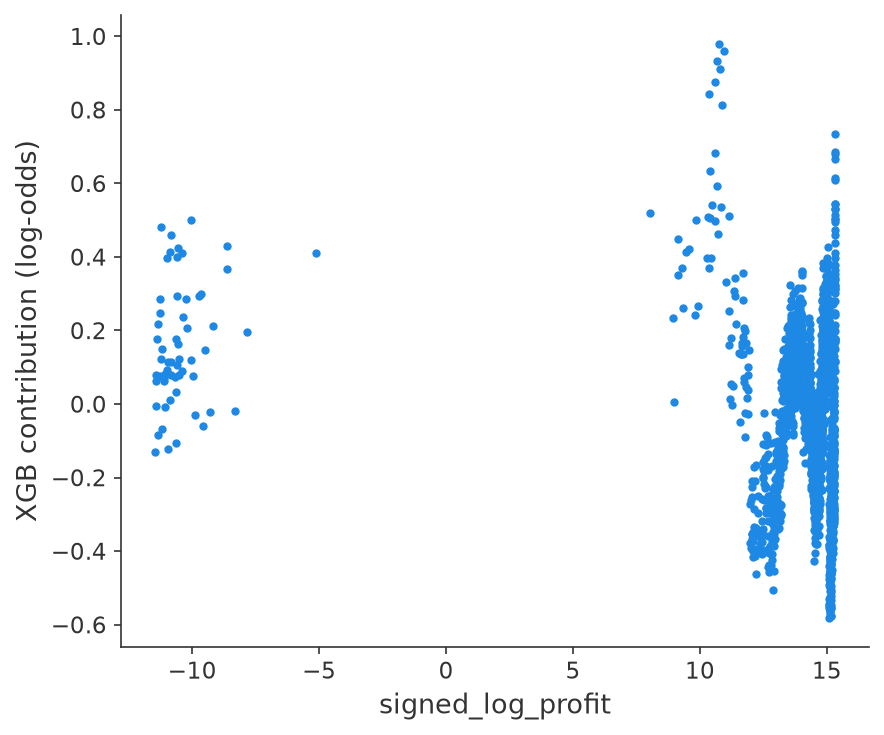

In [8]:
for filename in ['shap_summary_bar.png', 'shap_beeswarm.png',
                 'shap_dependence_utilization.png', 'shap_dependence_profit.png']:
    display(Image(filename=str(OUTPUTS / 'shap_plots' / filename)))


The prespecified candidate is an evaluated option. A learned portfolio rate can match or outperform it. New untouched data or nested candidate selection is required for a selected-champion claim.